<a href="https://colab.research.google.com/github/misalkaran7/Flight_Delay_Prediction/blob/main/PA_CA3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Flight Arrival Delay Prediction: Model Development & Multi-Dataset Comparison

### Step 1: Download the 3 Kaggle Datasets

In [ ]:
import os
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# Download Dataset 1
path_1 = kagglehub.dataset_download("hrishitpatil/flight-data-2024")
print("Dataset 1 Path:", path_1)

# Download Dataset 2
path_2 = kagglehub.dataset_download("niszarkiah/flight-dataset")
print("Dataset 2 Path:", path_2)

100%|██████████| 270M/270M [00:04<00:00, 58.9MB/s]

Extracting files...


Dataset 1 Path: /root/.cache/kagglehub/datasets/hrishitpatil/flight-data-2024/versions/2


100%|██████████| 11.1M/11.1M [00:00<00:00, 55.9MB/s]

Extracting files...


Dataset 2 Path: /root/.cache/kagglehub/datasets/niszarkiah/flight-dataset/versions/1


### Step 2: Load and Inspect the Datasets
We will find the main CSV files within the downloaded directories and read them into pandas DataFrames.

In [ ]:
def find_csv(folder_path):
    for root, dirs, files in os.walk(folder_path):
        for file in files:
            if file.endswith('.csv'):
                return os.path.join(root, file)
    return None

csv_1 = find_csv(path_1)
csv_2 = find_csv(path_2)

df1 = pd.read_csv(csv_1) if csv_1 else pd.DataFrame()
df2 = pd.read_csv(csv_2) if csv_2 else pd.DataFrame()

print("Dataset 1 columns:", df1.columns.tolist()[:10])
print("Dataset 2 columns:", df2.columns.tolist()[:10])

Dataset 1 columns: ['year', 'month', 'day_of_month', 'day_of_week', 'fl_date', 'op_unique_carrier', 'op_carrier_fl_num', 'origin', 'origin_city_name', 'origin_state_nm']
Dataset 2 columns: ['year', 'month', 'day', 'dep_time', 'sched_dep_time', 'dep_delay', 'arr_time', 'sched_arr_time', 'arr_delay', 'carrier']


### Step 3: Train and Evaluate Models
We will define a standardized preprocessing, training, and evaluation pipeline mapping the unique feature names of each dataset to a binary target (flight delayed vs. on-time).

In [ ]:
def process_and_evaluate(df, label_col, numerical_features, categorical_features, dataset_name):
    if df.empty:
        print(f"{dataset_name} is empty.")
        return {}

    # Ensure we have at least one feature to train on
    total_features = numerical_features + categorical_features
    if not total_features:
        print(f"No valid features provided/found for {dataset_name}. Skipping.")
        return {}

    # Handle missing targets
    df = df.dropna(subset=[label_col])

    # If target is continuous, convert to binary (delay > 15 mins = 1, else 0)
    if df[label_col].nunique() > 2:
        y = (df[label_col] > 15).astype(int)
    else:
        y = df[label_col].astype(int)

    X = df[total_features].copy()

    # Handle missing values
    for col in numerical_features:
        X[col] = X[col].fillna(X[col].median())
    for col in categorical_features:
        X[col] = X[col].fillna('Unknown').astype(str)

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numerical_features) if numerical_features else ('num', 'passthrough', []),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features) if categorical_features else ('cat', 'passthrough', [])
        ])

    models = {
        'Logistic Regression': LogisticRegression(max_iter=1000),
        'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
        'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
    }

    results = {}
    for model_name, model in models.items():
        clf = Pipeline(steps=[('preprocessor', preprocessor),
                              ('classifier', model)])
        clf.fit(X_train, y_train)
        preds = clf.predict(X_test)
        results[model_name] = {
            'Accuracy': accuracy_score(y_test, preds),
            'F1-Score': f1_score(y_test, preds, average='binary', zero_division=0)
        }
    return results

### Step 4: Compare Models across Datasets
We run the pipeline on each dataset dynamically using the best-matching delay indicators from their columns.

In [ ]:
# Helper function for model processing and evaluation
def process_and_evaluate(df, label_col, numerical_features, categorical_features, dataset_name):
    if df.empty:
        print(f"{dataset_name} is empty.")
        return {}

    # Ensure we have at least one feature to train on
    total_features = numerical_features + categorical_features
    if not total_features:
        print(f"No valid features provided/found for {dataset_name}. Skipping.")
        return {}

    # Handle missing targets
    df = df.dropna(subset=[label_col])

    # If target is continuous, convert to binary (delay > 15 mins = 1, else 0)
    if df[label_col].nunique() > 2:
        y = (df[label_col] > 15).astype(int)
    else:
        y = df[label_col].astype(int)

    X = df[total_features].copy()

    # Handle missing values
    for col in numerical_features:
        X[col] = X[col].fillna(X[col].median())
    for col in categorical_features:
        X[col] = X[col].fillna('Unknown').astype(str)

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numerical_features) if numerical_features else ('num', 'passthrough', []),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features) if categorical_features else ('cat', 'passthrough', [])
        ])

    models = {
        'Logistic Regression': LogisticRegression(max_iter=1000),
        'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
        'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
    }

    results = {}
    for model_name, model in models.items():
        clf = Pipeline(steps=[('preprocessor', preprocessor),
                              ('classifier', model)])
        clf.fit(X_train, y_train)
        preds = clf.predict(X_test)
        results[model_name] = {
            'Accuracy': accuracy_score(y_test, preds),
            'F1-Score': f1_score(y_test, preds, average='binary', zero_division=0)
        }
    return results

# Map appropriate columns dynamically matching case-insensitive schemas
def get_existing_cols(df, candidates):
    return [col for col in df.columns if col.lower() in [c.lower() for c in candidates]]

# Map features for Dataset 1
num_feat_1 = get_existing_cols(df1, ['distance', 'depdelay', 'crsdeptime', 'dep_delay', 'scheduled_duration'])
cat_feat_1 = get_existing_cols(df1, ['carrier', 'reporting_airline', 'uniquecarrier', 'op_unique_carrier'])
target_1 = 'ArrDelay' if 'ArrDelay' in df1.columns else ('arr_delay' if 'arr_delay' in df1.columns else (df1.columns[-1] if len(df1.columns) > 0 else None))

# Map features for Dataset 2
num_feat_2 = get_existing_cols(df2, ['distance', 'departuredelay', 'scheduledduration', 'dep_delay'])
cat_feat_2 = get_existing_cols(df2, ['airline', 'carrier'])
target_2 = 'ArrivalDelay' if 'ArrivalDelay' in df2.columns else ('arr_delay' if 'arr_delay' in df2.columns else (df2.columns[-1] if len(df2.columns) > 0 else None))

# Run evaluation
results_1 = process_and_evaluate(df1.head(10000), target_1, num_feat_1, cat_feat_1, "Dataset 1") if target_1 else {}
results_2 = process_and_evaluate(df2.head(10000), target_2, num_feat_2, cat_feat_2, "Dataset 2") if target_2 else {}

# Combine results
comparison_list = []
for ds_name, res in [("Dataset 1", results_1), ("Dataset 2", results_2)]:
    for model_name, metrics in res.items():
        comparison_list.append({
            'Dataset': ds_name,
            'Model': model_name,
            'Accuracy': metrics['Accuracy'],
            'F1-Score': metrics['F1-Score']
        })

comparison_df = pd.DataFrame(comparison_list)
display(comparison_df)

,Dataset,Model,Accuracy,F1-Score
0,Dataset 1,Logistic Regression,0.922256,0.788382
1,Dataset 1,Decision Tree,0.917683,0.763158
2,Dataset 1,Random Forest,0.920224,0.777935
3,Dataset 2,Logistic Regression,0.934717,0.797488
4,Dataset 2,Decision Tree,0.938765,0.811820
5,Dataset 2,Random Forest,0.935223,0.796825


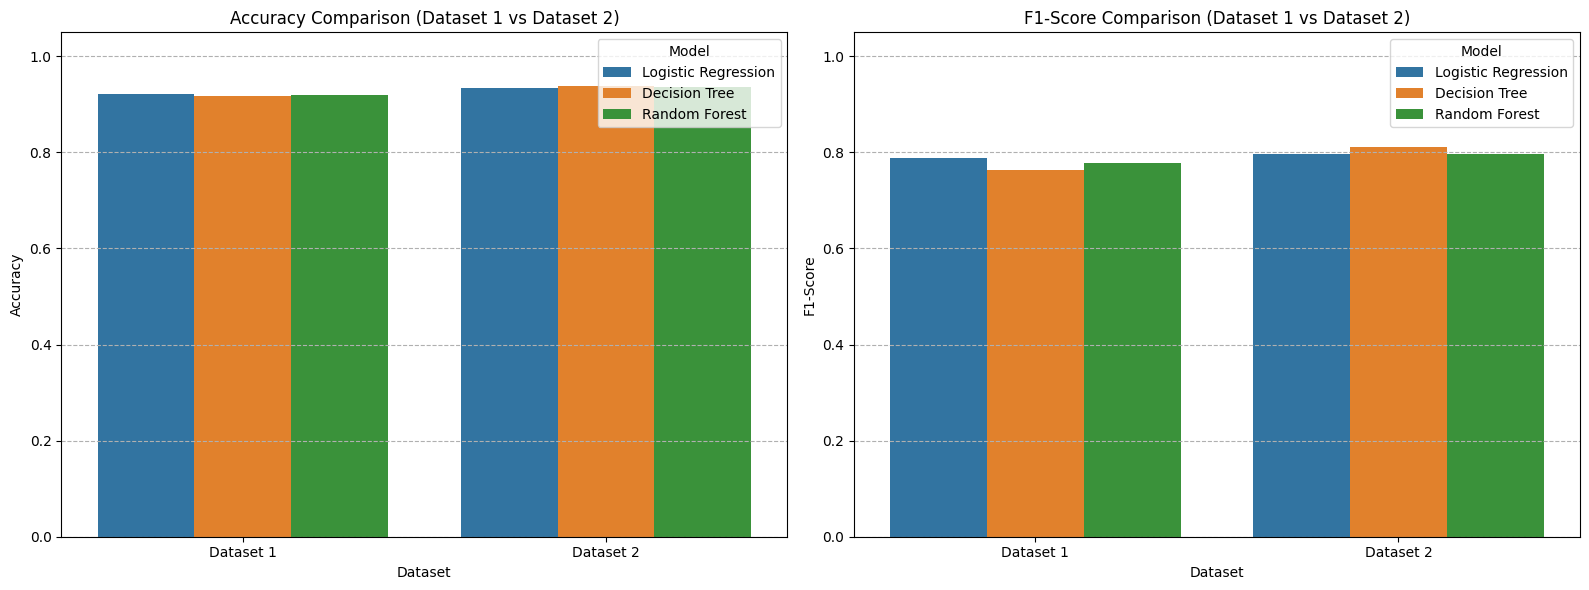

In [ ]:
# Visualization for 2 datasets
if not comparison_df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    sns.barplot(x='Dataset', y='Accuracy', hue='Model', data=comparison_df, ax=axes[0])
    axes[0].set_title('Accuracy Comparison (Dataset 1 vs Dataset 2)')
    axes[0].set_ylim(0.0, 1.05)
    axes[0].grid(axis='y', linestyle='--')

    sns.barplot(x='Dataset', y='F1-Score', hue='Model', data=comparison_df, ax=axes[1])
    axes[1].set_title('F1-Score Comparison (Dataset 1 vs Dataset 2)')
    axes[1].set_ylim(0.0, 1.05)
    axes[1].grid(axis='y', linestyle='--')

    plt.tight_layout()
    plt.show()

### Step 5: Advanced Model Evaluation for the Best Model
We will evaluate the best-performing model (**Decision Tree Classifier** on **Dataset 2**) using a confusion matrix, precision, recall, and ROC-AUC metrics to look closer at true positives, false positives, and false negatives.

=== Classification Report for Best Model ===
              precision    recall  f1-score   support

     On-Time       0.94      0.98      0.96      1622
     Delayed       0.90      0.74      0.81       354

    accuracy                           0.94      1976
   macro avg       0.92      0.86      0.89      1976
weighted avg       0.94      0.94      0.94      1976

ROC-AUC Score: 0.9366



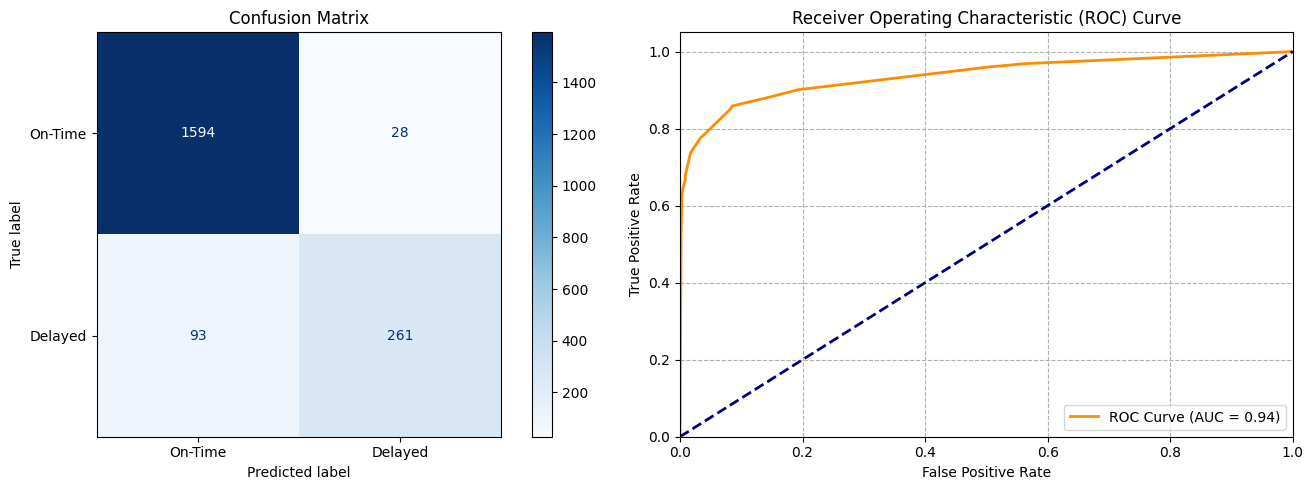

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve, ConfusionMatrixDisplay

# Prepare target and features for Dataset 2
df2_sample = df2.head(10000).dropna(subset=[target_2])
y2 = (df2_sample[target_2] > 15).astype(int) if df2_sample[target_2].nunique() > 2 else df2_sample[target_2].astype(int)

total_features_2 = num_feat_2 + cat_feat_2
X2 = df2_sample[total_features_2].copy()

for col in num_feat_2:
    X2[col] = X2[col].fillna(X2[col].median())
for col in cat_feat_2:
    X2[col] = X2[col].fillna('Unknown').astype(str)

X_train2, X_test2, y_train2, y_test2 = train_test_split(X2, y2, test_size=0.2, random_state=42, stratify=y2)

# Best Model Pipeline setup
best_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_feat_2) if num_feat_2 else ('num', 'passthrough', []),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_feat_2) if cat_feat_2 else ('cat', 'passthrough', [])
    ])

best_model = DecisionTreeClassifier(max_depth=5, random_state=42)
best_pipeline = Pipeline(steps=[('preprocessor', best_preprocessor), ('classifier', best_model)])
best_pipeline.fit(X_train2, y_train2)

# Predict and evaluate
y_pred = best_pipeline.predict(X_test2)
y_proba = best_pipeline.predict_proba(X_test2)[:, 1]

# Detailed Classification Metrics
print("=== Classification Report for Best Model ===")
print(classification_report(y_test2, y_pred, target_names=['On-Time', 'Delayed']))

roc_auc = roc_auc_score(y_test2, y_proba)
print(f"ROC-AUC Score: {roc_auc:.4f}\n")

# Plot Confusion Matrix and ROC Curve side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix Plot
cm = confusion_matrix(y_test2, y_pred)
cmd = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['On-Time', 'Delayed'])
cmd.plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title('Confusion Matrix')

# ROC Curve Plot
fpr, tpr, thresholds = roc_curve(y_test2, y_proba)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.2f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic (ROC) Curve')
axes[1].legend(loc="lower right")
axes[1].grid(True, linestyle='--')

plt.tight_layout()
plt.show()